In [84]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

# 1. Memuat Dataset MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Pra-pengolahan Data (Normalisasi & Flattening)
# Mengubah tipe data ke float32 dan menskalakan nilai piksel dari [0, 255] ke [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Mengubah dimensi gambar (28, 28) menjadi vektor 1D (784)
x_train = x_train.reshape(-1, 28 * 28)
x_test = x_test.reshape(-1, 28 * 28)

print(f"Bentuk data latih: {x_train.shape}")
print(f"Bentuk data uji: {x_test.shape}")

# 3. Membangun Arsitektur Model ANN
model = models.Sequential([
    # Input Layer + Hidden Layer 1
    layers.Dense(512, activation='relu', input_shape=(784,)),
    layers.BatchNormalization(),  # Menstabilkan distribusi aktivasi
    layers.Dropout(0.3),          # Mencegah overfitting dengan mematikan 30% neuron acak

    # Hidden Layer 2
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    # Hidden Layer 3
    layers.Dense(128, activation='relu'),

    # Output Layer (10 kelas untuk digit 0-9)
    layers.Dense(10, activation='softmax')
])

# Menampilkan ringkasan arsitektur
model.summary()

# 4. Kompilasi Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy', # Digunakan karena label berupa integer (0-9)
    metrics=['accuracy']
)

# 5. Pelatihan Model (Training)
# Menggunakan EarlyStopping agar pelatihan berhenti otomatis jika akurasi validasi tidak membaik
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1, # 10% data latih dipakai untuk validasi
    callbacks=[early_stop],
    verbose=1
)

# 6. Evaluasi Model pada Data Uji
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nAkurasi pada Data Uji (Test Accuracy): {test_acc * 100:.2f}%")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Bentuk data latih: (60000, 784)
Bentuk data uji: (10000, 784)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 570,506 (2.18 MB)

 Trainable params: 568,970 (2.17 MB)

 Non-trainable params: 1,536 (6.00 KB)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9144 - loss: 0.2742 - val_accuracy: 0.9670 - val_loss: 0.1068
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9581 - loss: 0.1323 - val_accuracy: 0.9720 - val_loss: 0.0916
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9672 - loss: 0.1045 - val_accuracy: 0.9773 - val_loss: 0.0759
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9722 - loss: 0.0866 - val_accuracy: 0.9785 - val_loss: 0.0732
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9758 - loss: 0.0745 - val_accuracy: 0.9780 - val_loss: 0.0725
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9790 - loss: 0.0656 - val_accuracy: 0.9808 - val_loss: 0.0731
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9794 - loss: 0.0625 - val_accuracy: 0.9820 - val_loss: 0.0655
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9811 - loss: 0.0547 - val_a

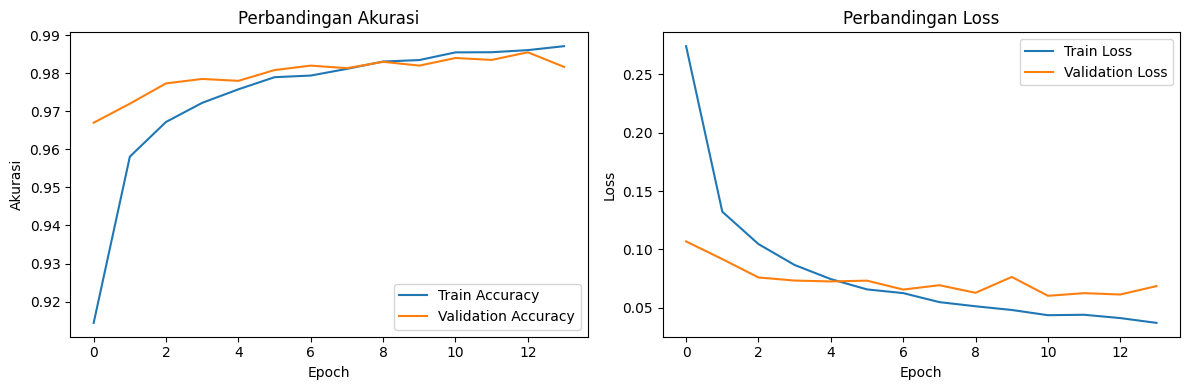

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
Label Sebenarnya : [7 2 1 0 4]
Hasil Prediksi   : [7 2 1 0 4]


In [85]:
# Plot Kurva Akurasi & Loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Perbandingan Akurasi')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Perbandingan Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Uji Prediksi pada 5 Sampel Acak
predictions = model.predict(x_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

print("Label Sebenarnya :", y_test[:5])
print("Hasil Prediksi   :", predicted_labels)